In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np
import smarts_cerebellum.globals as gl

atlas = 'NettekovenLeftRight'
rois = ['cerebellum_L', 'cerebellum_R']
colours = ['green', 'r', 'blue']

segment = 'GM'

# observed means
patients_actual = pd.read_csv(os.path.join(gl.baseDir, f'MNISymC_{segment}', f'summary_MNISymC_Nettekoven_LeftRight_{segment}_mod.tsv'), sep = '\t')
patients_actual = patients_actual[patients_actual.isPatient == 1]
controls_actual = pd.read_csv(os.path.join(gl.baseDir, f'MNISymC_{segment}', f'summary_MNISymC_Nettekoven_LeftRight_{segment}_mod.tsv'), sep = '\t')
controls_actual = controls_actual[controls_actual.isPatient == 0]

# estimated means
patients_lme = pd.read_csv(os.path.join(gl.baseDir, 'lme', f'patients_MNISymC_{segment}_mod_Nettekoven_LeftRight_lme.tsv'), sep = '\t')
patients_lme = patients_lme.drop(columns = ['subj_id', 'random_intercept', 'Unnamed: 0']).drop_duplicates().reset_index(drop = True)
controls_lme = pd.read_csv(os.path.join(gl.baseDir, 'lme', f'controls_MNISymC_{segment}_mod_Nettekoven_LeftRight_lme.tsv'), sep = '\t')
controls_lme = controls_lme.drop(columns = ['subj_id', 'random_intercept', 'Unnamed: 0']).drop_duplicates().reset_index(drop = True)



# get hemisphere
patients_lme['hemisphere'] = patients_lme.regionname.str.lower().str[-1]
controls_lme['hemisphere'] = controls_lme.regionname.str.lower().str[-1]
patients_actual['hemisphere'] = patients_actual.regionname.str.lower().str[-1]
controls_actual['hemisphere'] = controls_actual.regionname.str.lower().str[-1]

# for controls, get bihemispheric mean
controls_lme = controls_lme.sort_values('Week')
controls_actual = controls_actual.sort_values('Week')
controls_actual = controls_actual.groupby(['Week'], as_index = False)['mean'].mean()

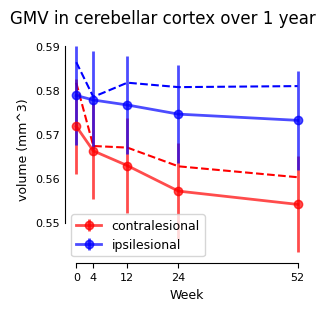

In [38]:
fig, ax = plt.subplots(figsize=(3, 3), sharey = True, constrained_layout = True)

for i, H in enumerate(gl.Hem):
    patients_lme_h = patients_lme[patients_lme.hemisphere == H].sort_values('Week')
    patients_actual_h = patients_actual[patients_actual.hemisphere == H].sort_values('Week')
    patients_actual_h = patients_actual_h.groupby(['Week'], as_index = False)['mean'].mean()

    ax.errorbar(x=patients_lme_h['Week'], y=patients_lme_h['beta'], yerr = patients_lme_h['se'], fmt = '-o', color = colours[i+1], linewidth = 2, label = 'contralesional' if H == 'l' else 'ipsilesional', alpha = .7)

    ax.plot(patients_actual_h['Week'], patients_actual_h['mean'], color = colours[i+1], linestyle = '--')


for i in range(2):
    ax.set_xticks(gl.weeks)
    ax.set_xlabel("Week")
ax.tick_params(axis = 'y', length = 0)

ax.set_ylabel('volume (mm^3)')

fig.suptitle(f'GMV in cerebellar cortex over 1 year')
plt.legend(loc = 'lower left')
sns.despine(trim = True)

fig.savefig('figure/lme_GMV_cerebellum.pdf')

plt.show()